## HW6 APPM-5370
Jenn Kaphammer

In [18]:
import numpy as np
from scipy.optimize import brentq
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)

### Q1b - root-finding

In [4]:
#quotient
def f(T):
    return 0.5 * (1 - np.exp(-0.5 * T))

def g(T):
    return 1 - np.exp(-0.5 * T) + 0.5*T + 5

def f_prime(T):
    return 0.25 * np.exp(-0.5 * T)

def g_prime(T):
    return 0.5 * np.exp(-0.5 * T) + 0.5

def equation(T):
    return f_prime(T) * g(T) - f(T) * g_prime(T)

T_star = brentq(equation, 0, 20)

In [5]:
T_star = brentq(equation, 0, 20)
R_star = f(T_star) / g(T_star)

print("Optimal waiting time:", T_star)
print("Optimal intake rate:", R_star)

Optimal waiting time: 4.181434810310963
Optimal intake rate: 0.05500115972326258


### Q1c - Foraging simulations

In [11]:
#based on bandit.py from Canvas
import numpy as np

def run_foraging(T, n_visits=400_000, p_H=0.5, rho=0.5, tau=5, rng=None):
    #option to set seed
    rng = rng or np.random.default_rng()
    high = rng.random(n_visits) < p_H
    #exponential
    food_times = rng.exponential(scale=1/rho, size=n_visits)
    #if food was discovered before T
    found_food = high & (food_times <= T)
    search_time = np.where(
        high,
        np.minimum(food_times, T),
        T
    )
    # add travel time
    total_food = np.sum(found_food)
    total_time = np.sum(search_time) + n_visits * tau

    return total_food/total_time

def theoretical_rate(T, p_H=0.5, rho=0.5, tau=5):
    num = p_H * (1 - np.exp(-rho * T))
    denom = (
        (p_H / rho) * (1 - np.exp(-rho * T))
        + (1 - p_H) * T
        + tau
    )
    return num/denom

In [12]:
for T in [2, T_star, 10]:
    simulated = run_foraging(T, rng=rng)
    theoretical = theoretical_rate(T)

    print("T =", T)
    print("Simulated rate =", simulated)
    print("Theoretical rate =", theoretical)
    print()

T = 2
Simulated rate = 0.047715584626207966
Theoretical rate = 0.04765599126414329

T = 4.181434810310963
Simulated rate = 0.05501992419130348
Theoretical rate = 0.05500115972326258

T = 10
Simulated rate = 0.04532734553249578
Theoretical rate = 0.04517594723987209



The simulated results agree with the theoretical baseline. Out of the 3 $T$s, $T^*$ performed the best.

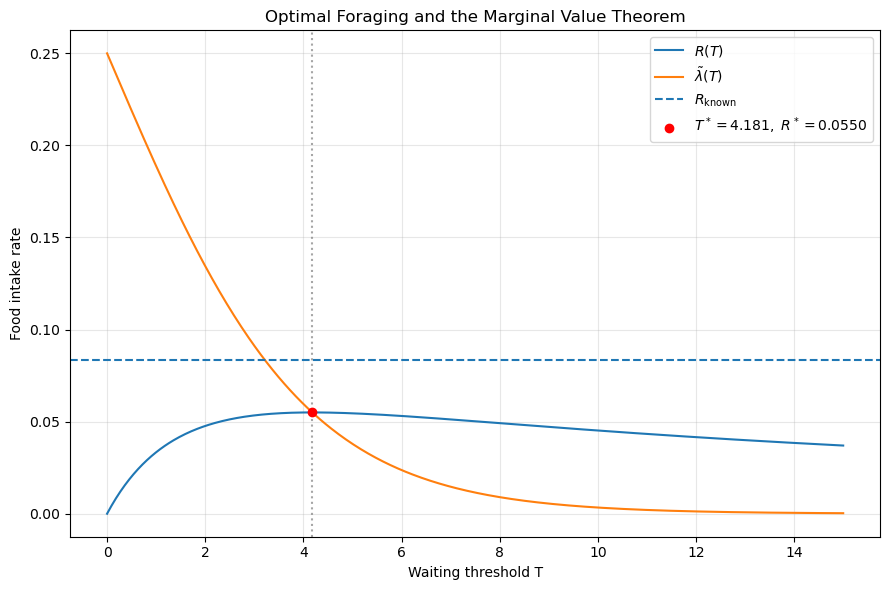

In [16]:
def lambda_tilde(T, p_H=0.5, rho=0.5):
    numerator = rho * p_H * np.exp(-rho * T)
    denominator = p_H * np.exp(-rho * T) + 1 - p_H
    return numerator / denominator

T_values = np.linspace(0, 15, 500)

R_values = theoretical_rate(T_values)
lambda_values = lambda_tilde(T_values)

R_star = theoretical_rate(T_star)
R_known = 0.5 / 6

plt.figure(figsize=(9, 6))

plt.plot(T_values, R_values, label=r"$R(T)$")
plt.plot(T_values, lambda_values, label=r"$\tilde{\lambda}(T)$")
plt.axhline(R_known, linestyle="--", label=r"$R_{\mathrm{known}}$")

# Mark the optimum
plt.scatter(T_star, R_star, color="red", zorder=5,
            label=rf"$T^*={T_star:.3f},\ R^*={R_star:.4f}$")

plt.axvline(T_star, color="gray", linestyle=":", alpha=0.7)

plt.xlabel("Waiting threshold T")
plt.ylabel("Food intake rate")
plt.title("Optimal Foraging and the Marginal Value Theorem")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Q2c - Game posession simulations

In [ ]:
#TODO